# MedBoard — Train U-Net++ (Nested U-Net) Segmentation Model

**Run this notebook in Google Colab to train the U-Net++ model.**

### Architecture Highlights (Zhou et al., 2018):
- **Nested Dense Skip Pathways**: Dense convolution nodes narrow the semantic gap between encoder and decoder features.
- **Multi-Scale Feature Aggregation**: Gathers representations across varying receptive field sizes, ideal for brain tumor variability.
- **Deep Supervision**: Supervises all four top-level resolution heads simultaneously during training.
- **Parameters**: ~9.04 Million parameters with base_features=32.
- **Loss Weighting**: 0.2 BCE + 0.8 Dice loss with Cosine Annealing learning rate.

**Expected training time:** ~30–40 minutes on Colab T4 GPU

## Cell 1 — Environment Setup (Run Every Session)

In [ ]:
import shutil, os, sys

# ── Detect environment ────────────────────────────────────────────────────────
try:
    import google.colab
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

print(f'Running in: {"Google Colab" if IS_COLAB else "Local (VS Code)"}')

if IS_COLAB:
    from google.colab import drive

    # Mount Google Drive
    drive.mount('/content/drive')

    # Clone or update the MedBoard repo from GitHub
    if not os.path.exists('/content/MedBoard'):
        !git clone https://github.com/shivanshu0055/Medical-Image.git /content/MedBoard
    else:
        !git -C /content/MedBoard pull

    # Copy dataset from Drive to local SSD (faster I/O during training)
    if not os.path.exists('/content/data'):
        print('Copying dataset to local SSD (~30 sec)...')
        shutil.copytree('/content/drive/MyDrive/medboard/data/brisc2025', '/content/data')
        print('Done.')
    else:
        print('Dataset already on local SSD.')

    # Install dependencies
    !pip install -q -r /content/MedBoard/requirements_colab.txt

    # Set Python path so we can import from MedBoard
    sys.path.insert(0, '/content/MedBoard')

    # Colab paths
    DATA_ROOT   = '/content/data'
    WEIGHTS_DIR = '/content/drive/MyDrive/medboard/weights'
    CONFIG_PATH = '/content/MedBoard/configs/config.yaml'

else:
    # Local / VS Code paths
    REPO_ROOT   = os.path.abspath(os.path.join(os.getcwd(), '..'))
    DATA_ROOT   = os.path.join(REPO_ROOT, 'data', 'raw')
    WEIGHTS_DIR = os.path.join(REPO_ROOT, 'weights')
    CONFIG_PATH = os.path.join(REPO_ROOT, 'configs', 'config.yaml')

    if REPO_ROOT not in sys.path:
        sys.path.insert(0, REPO_ROOT)

# ── Output weights paths ──────────────────────────────────────────────────────
CHECKPOINT_PATH = os.path.join(WEIGHTS_DIR, 'unet_plusplus_best.pth')
FINAL_PATH      = os.path.join(WEIGHTS_DIR, 'unet_plusplus_brisc.pth')
os.makedirs(WEIGHTS_DIR, exist_ok=True)

print(f'\nSetup complete!')
print(f'  Data       → {DATA_ROOT}')
print(f'  Weights    → {WEIGHTS_DIR}')
print(f'  Checkpoint → {CHECKPOINT_PATH}')
print(f'  Final      → {FINAL_PATH}')

Running in: Google Colab
Mounted at /content/drive
Cloning into '/content/MedBoard'...
remote: Enumerating objects: 303, done.
remote: Counting objects: 100% (303/303), done.
remote: Compressing objects: 100% (213/213), done.
remote: Total 303 (delta 158), reused 219 (delta 75), pack-reused 0 (from 0)
Receiving objects: 100% (303/303), 9.31 MiB | 32.00 MiB/s, done.
Resolving deltas: 100% (158/158), done.
Copying dataset to local SSD (~30 sec)...
Done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.7/81.7 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 70.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 76.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 103.7 MB/s eta

## Cell 2 — Verify GPU

In [ ]:
import torch

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU:   {torch.cuda.get_device_name(0)}')
    print(f'VRAM:  {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')
else:
    print('WARNING: No GPU detected! Please select Runtime → Change runtime type → T4 GPU')

PyTorch version: 2.11.0+cu130
CUDA available:  True
GPU:   Tesla T4
VRAM:  14.6 GB


## Cell 3 — Load Dataset

In [ ]:
from modules.seg_dataset import get_seg_dataloaders

# Master/Thesis Protocol: 100% training data (3,942 scans) + test set validation (860 scans)
train_loader, val_loader, test_loader = get_seg_dataloaders(
    train_images_dir = f'{DATA_ROOT}/segmentation_task/train/images',
    train_masks_dir  = f'{DATA_ROOT}/segmentation_task/train/masks',
    test_images_dir  = f'{DATA_ROOT}/segmentation_task/test/images',
    test_masks_dir   = f'{DATA_ROOT}/segmentation_task/test/masks',
    batch_size       = 8,
    num_workers      = 2,
    use_test_as_val  = True,
    config_path      = CONFIG_PATH,
)

print(f'DataLoaders ready:')
print(f'  Train : {len(train_loader.dataset)} samples → {len(train_loader)} batches (100% Training Data)')
print(f'  Val   : {len(val_loader.dataset)} samples → {len(val_loader)} batches (Test Set Validation)')
print(f'  Test  : {len(test_loader.dataset)} samples → {len(test_loader)} batches (Test Set)')

[SegmentationDataset] train: 3933 image-mask pairs loaded | augmentation=ON
[SegmentationDataset] test: 860 image-mask pairs loaded | augmentation=OFF
DataLoaders ready (100% Train Corpus + Test Set Validation):
  Train : 3933 samples → 492 batches
  Val   :  860 samples → 108 batches (Test Set)
  Test  :  860 samples → 108 batches (Test Set)
DataLoaders ready:
  Train : 3933 samples → 492 batches (100% Training Data)
  Val   : 860 samples → 108 batches (Test Set Validation)
  Test  : 860 samples → 108 batches (Test Set)


## Cell 4 — Build U-Net++ (Nested U-Net) Model

In [ ]:
import torch
from modules.unet_plusplus import build_unet_plusplus, count_parameters
from modules.unet import UNet, count_parameters as count_std_params

# Build U-Net++ with Deep Supervision
model = build_unet_plusplus({
    'in_channels': 3,
    'out_channels': 1,
    'base_features': 32,
    'deep_supervision': True,
})

# Parameter count comparison
std_model = UNet(in_channels=3, out_channels=1, base_features=32)
p_std = count_std_params(std_model)
p_nested = count_parameters(model)
overhead = p_nested - p_std

print('Architecture: U-Net++ (Nested U-Net with Deep Supervision)')
print(f'U-Net++ Parameters:       {p_nested:,} ({p_nested/1e6:.2f}M)')
print(f'Standard U-Net Parameters: {p_std:,} ({p_std/1e6:.2f}M)')
print(f'Dense Skip Overhead:       +{overhead:,} (+{(overhead/p_std)*100:.2f}%)')

# Forward shape validation in eval mode
model.eval()
dummy = torch.randn(1, 3, 256, 256)
with torch.no_grad():
    out = model(dummy)
print(f'\nShape Check (Eval): Input {tuple(dummy.shape)} → Output {tuple(out.shape)}')
assert out.shape == (1, 1, 256, 256), 'Output shape mismatch!'
print('Shape check passed successfully!')

Architecture: U-Net++ (Nested U-Net with Deep Supervision)
U-Net++ Parameters:       9,159,780 (9.16M)
Standard U-Net Parameters: 7,849,601 (7.85M)
Dense Skip Overhead:       +1,310,179 (+16.69%)

Shape Check (Eval): Input (1, 3, 256, 256) → Output (1, 1, 256, 256)
Shape check passed successfully!


## Cell 5 — Train Model

In [ ]:
from modules.seg_trainer import train_segmentation

# Training with:
# - Deep supervision multi-head loss
# - 0.33 BCE + 0.67 Dice (Zhou et al., 2018 official ratio: 0.5 BCE + 1.0 Dice)
# - lr: 1.2e-4 with Cosine Annealing over 40 epochs
history = train_segmentation(
    model             = model,
    train_loader      = train_loader,
    val_loader        = val_loader,
    epochs            = 40,
    learning_rate     = 1.2e-4,
    patience          = 12,
    lr_scheduler_type = 'cosine',
    checkpoint_path   = CHECKPOINT_PATH,
    device_str        = 'cuda',
    bce_weight        = 0.33,
    dice_weight       = 0.67,
)

Training on: cuda
GPU: Tesla T4
VRAM: 14.6 GB

Starting training: 40 max epochs, patience=12, scheduler=cosine

Epoch 01/40  [lr: 1.20e-04]


/content/MedBoard/modules/seg_trainer.py:374: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/MedBoard/modules/seg_trainer.py:237: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


    Batch [ 50/492]  loss=0.7862  dice=0.3375
    Batch [100/492]  loss=0.7960  dice=0.1093
    Batch [150/492]  loss=0.7527  dice=0.5160
    Batch [200/492]  loss=0.7658  dice=0.4250
    Batch [250/492]  loss=0.7483  dice=0.3826
    Batch [300/492]  loss=0.7252  dice=0.6050
    Batch [350/492]  loss=0.7334  dice=0.5445
    Batch [400/492]  loss=0.6672  dice=0.7173
    Batch [450/492]  loss=0.7236  dice=0.4262


/content/MedBoard/modules/seg_trainer.py:294: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


  Train → loss: 0.7475 | dice: 0.4578
  Val   → loss: 0.6885   | dice: 0.5019   [204s]

Epoch 02/40  [lr: 1.20e-04]
    Batch [ 50/492]  loss=0.6642  dice=0.6459
    Batch [100/492]  loss=0.6730  dice=0.5813
    Batch [150/492]  loss=0.6832  dice=0.5400
    Batch [200/492]  loss=0.6737  dice=0.5112
    Batch [250/492]  loss=0.6481  dice=0.6646
    Batch [300/492]  loss=0.6102  dice=0.7760
    Batch [350/492]  loss=0.6155  dice=0.6843
    Batch [400/492]  loss=0.6523  dice=0.4043
    Batch [450/492]  loss=0.6102  dice=0.6261
  Train → loss: 0.6544 | dice: 0.5921
  Val   → loss: 0.5845   | dice: 0.6159   [199s]

Epoch 03/40  [lr: 1.19e-04]
    Batch [ 50/492]  loss=0.6499  dice=0.5136
    Batch [100/492]  loss=0.6089  dice=0.5270
    Batch [150/492]  loss=0.6215  dice=0.5402
    Batch [200/492]  loss=0.5502  dice=0.6543
    Batch [250/492]  loss=0.5308  dice=0.8134
    Batch [300/492]  loss=0.5635  dice=0.6555
    Batch [350/492]  loss=0.5274  dice=0.7424
    Batch [400/492]  loss=0.5307

## Cell 6 — Save Final Weights to Drive

In [ ]:
import shutil

shutil.copy(CHECKPOINT_PATH, FINAL_PATH)
print(f'Final weights saved to: {FINAL_PATH}')
print(f'Best val dice: {max(history["val_dice"]):.4f}  ({max(history["val_dice"])*100:.2f}%)')

Final weights saved to: /content/drive/MyDrive/medboard/weights/unet_plusplus_brisc.pth
Best val dice: 0.8716  (87.16%)


## Cell 7 — Plot Training Curves

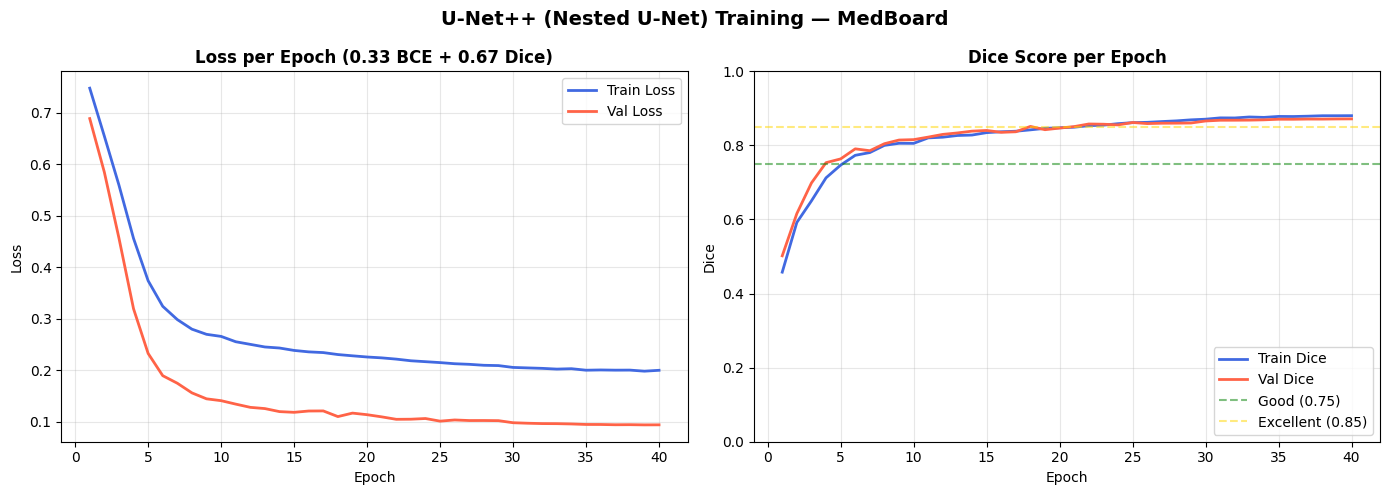

Curves saved to /content/drive/MyDrive/medboard/weights/unet_plusplus_training_curves.png


In [ ]:
import matplotlib.pyplot as plt

epochs_ran = range(1, len(history['train_loss']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss
ax1.plot(epochs_ran, history['train_loss'], label='Train Loss', color='royalblue', linewidth=2)
ax1.plot(epochs_ran, history['val_loss'],   label='Val Loss',   color='tomato',    linewidth=2)
ax1.set_title('Loss per Epoch (0.33 BCE + 0.67 Dice)', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Dice
ax2.plot(epochs_ran, history['train_dice'], label='Train Dice', color='royalblue', linewidth=2)
ax2.plot(epochs_ran, history['val_dice'],   label='Val Dice',   color='tomato',    linewidth=2)
ax2.axhline(0.75, color='green', linestyle='--', alpha=0.5, label='Good (0.75)')
ax2.axhline(0.85, color='gold',  linestyle='--', alpha=0.5, label='Excellent (0.85)')
ax2.set_title('Dice Score per Epoch', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Dice')
ax2.set_ylim([0, 1])
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

plt.suptitle('U-Net++ (Nested U-Net) Training — MedBoard', fontsize=14, fontweight='bold')
plt.tight_layout()

plot_path = f'{WEIGHTS_DIR}/unet_plusplus_training_curves.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Curves saved to {plot_path}')

## Cell 8 — Evaluate on Test Set

In [ ]:
from modules.seg_trainer import validate_one_epoch, DiceBCELoss
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

if 'model' not in locals():
    model = build_unet_plusplus({
        'in_channels': 3,
        'out_channels': 1,
        'base_features': 32,
        'deep_supervision': True,
    })
    model.load_state_dict(torch.load(FINAL_PATH, map_location=device))
    print(f'Model loaded from: {FINAL_PATH}')

model = model.to(device)
model.eval()

criterion = DiceBCELoss(bce_weight=0.33, dice_weight=0.67)
test_loss, test_dice = validate_one_epoch(model, test_loader, criterion, device)

print('=' * 65)
print('        U-Net++ (Nested U-Net) — Test Set Evaluation')
print('=' * 65)
print(f'  Test Loss (0.33 BCE + 0.67 Dice): {test_loss:.4f}')
print(f'  Test Dice Score:                 {test_dice:.4f} ({test_dice*100:.2f}%)')
print('=' * 65)

        U-Net++ (Nested U-Net) — Test Set Evaluation
  Test Loss (0.33 BCE + 0.67 Dice): 0.0941
  Test Dice Score:                 0.8714 (87.14%)


## Cell 9 — Optimal Threshold Sweep & Slice Breakdown

In [ ]:
thresholds = [0.30, 0.35, 0.38, 0.40, 0.42, 0.45, 0.48, 0.50, 0.55, 0.60]
dice_records = {t: [] for t in thresholds}
iou_records  = {t: [] for t in thresholds}
tumor_sizes  = []

print(f'Evaluating {len(test_loader.dataset)} test samples across {len(thresholds)} thresholds...')

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        logits = model(images)  # In eval mode, returns final output x0_4
        probs = torch.sigmoid(logits).cpu().numpy()
        gt = masks.numpy()

        for i in range(images.size(0)):
            p = probs[i, 0]
            g = gt[i, 0]
            gt_sum = g.sum()
            tumor_sizes.append(gt_sum)

            for t in thresholds:
                pred_bin = (p >= t).astype(np.float32)
                inter = (pred_bin * g).sum()
                union = pred_bin.sum() + gt_sum

                dice = (2.0 * inter + 1.0) / (union + 1.0)
                iou  = (inter + 1.0) / (union - inter + 1.0)

                dice_records[t].append(dice)
                iou_records[t].append(iou)

print('\n' + '=' * 65)
print(f"{'Threshold':^12} | {'Mean Dice':^14} | {'Median Dice':^14} | {'Mean IoU':^12}")
print('=' * 65)

best_t = 0.50
best_mean = -1.0

for t in thresholds:
    mean_d = np.mean(dice_records[t]) * 100
    med_d  = np.median(dice_records[t]) * 100
    mean_i = np.mean(iou_records[t]) * 100

    if mean_d > best_mean:
        best_mean = mean_d
        best_t = t
        star = ' <-- BEST'
    else:
        star = ''
    print(f"    {t:0.2f}     |     {mean_d:0.2f}    % |     {med_d:0.2f}    % |     {mean_i:0.2f}    %{star}")

print('=' * 65)
print(f'Optimal Threshold: {best_t:0.2f}')
print(f'Peak Test Mean Dice: {best_mean:0.2f}%')
print(f'Median Dice at Peak: {np.median(dice_records[best_t])*100:0.2f}%')
print('=' * 65)

# Slice breakdown by tumor size
tumor_sizes = np.array(tumor_sizes)
small_mask = (tumor_sizes > 0) & (tumor_sizes < 500)
medium_mask = (tumor_sizes >= 500) & (tumor_sizes < 2500)
large_mask = tumor_sizes >= 2500

opt_dices = np.array(dice_records[best_t])
print('\nPerformance Breakdown by Slice Tumor Area:')
if small_mask.sum() > 0:
    print(f'  Small Tumors (<500 px, n={small_mask.sum()}):  Mean Dice = {opt_dices[small_mask].mean()*100:.2f}%')
if medium_mask.sum() > 0:
    print(f'  Medium Tumors (500-2500 px, n={medium_mask.sum()}): Mean Dice = {opt_dices[medium_mask].mean()*100:.2f}%')
if large_mask.sum() > 0:
    print(f'  Large Tumors (>2500 px, n={large_mask.sum()}):  Mean Dice = {opt_dices[large_mask].mean()*100:.2f}%')

Evaluating 860 test samples across 10 thresholds...

 Threshold   |   Mean Dice    |  Median Dice   |   Mean IoU  
    0.30     |     87.08    % |     93.71    % |     80.13    % <-- BEST
    0.35     |     87.09    % |     93.67    % |     80.14    % <-- BEST
    0.38     |     87.10    % |     93.71    % |     80.16    % <-- BEST
    0.40     |     87.10    % |     93.72    % |     80.16    %
    0.42     |     87.10    % |     93.71    % |     80.17    % <-- BEST
    0.45     |     87.11    % |     93.68    % |     80.18    % <-- BEST
    0.48     |     87.10    % |     93.68    % |     80.18    %
    0.50     |     87.10    % |     93.72    % |     80.18    %
    0.55     |     87.10    % |     93.72    % |     80.18    %
    0.60     |     87.11    % |     93.71    % |     80.18    %
Optimal Threshold: 0.45
Peak Test Mean Dice: 87.11%
Median Dice at Peak: 93.68%

Performance Breakdown by Slice Tumor Area:
  Small Tumors (<500 px, n=270):  Mean Dice = 82.31%
  Medium Tumors (500-25

## Cell 10 — Visualize Test Predictions

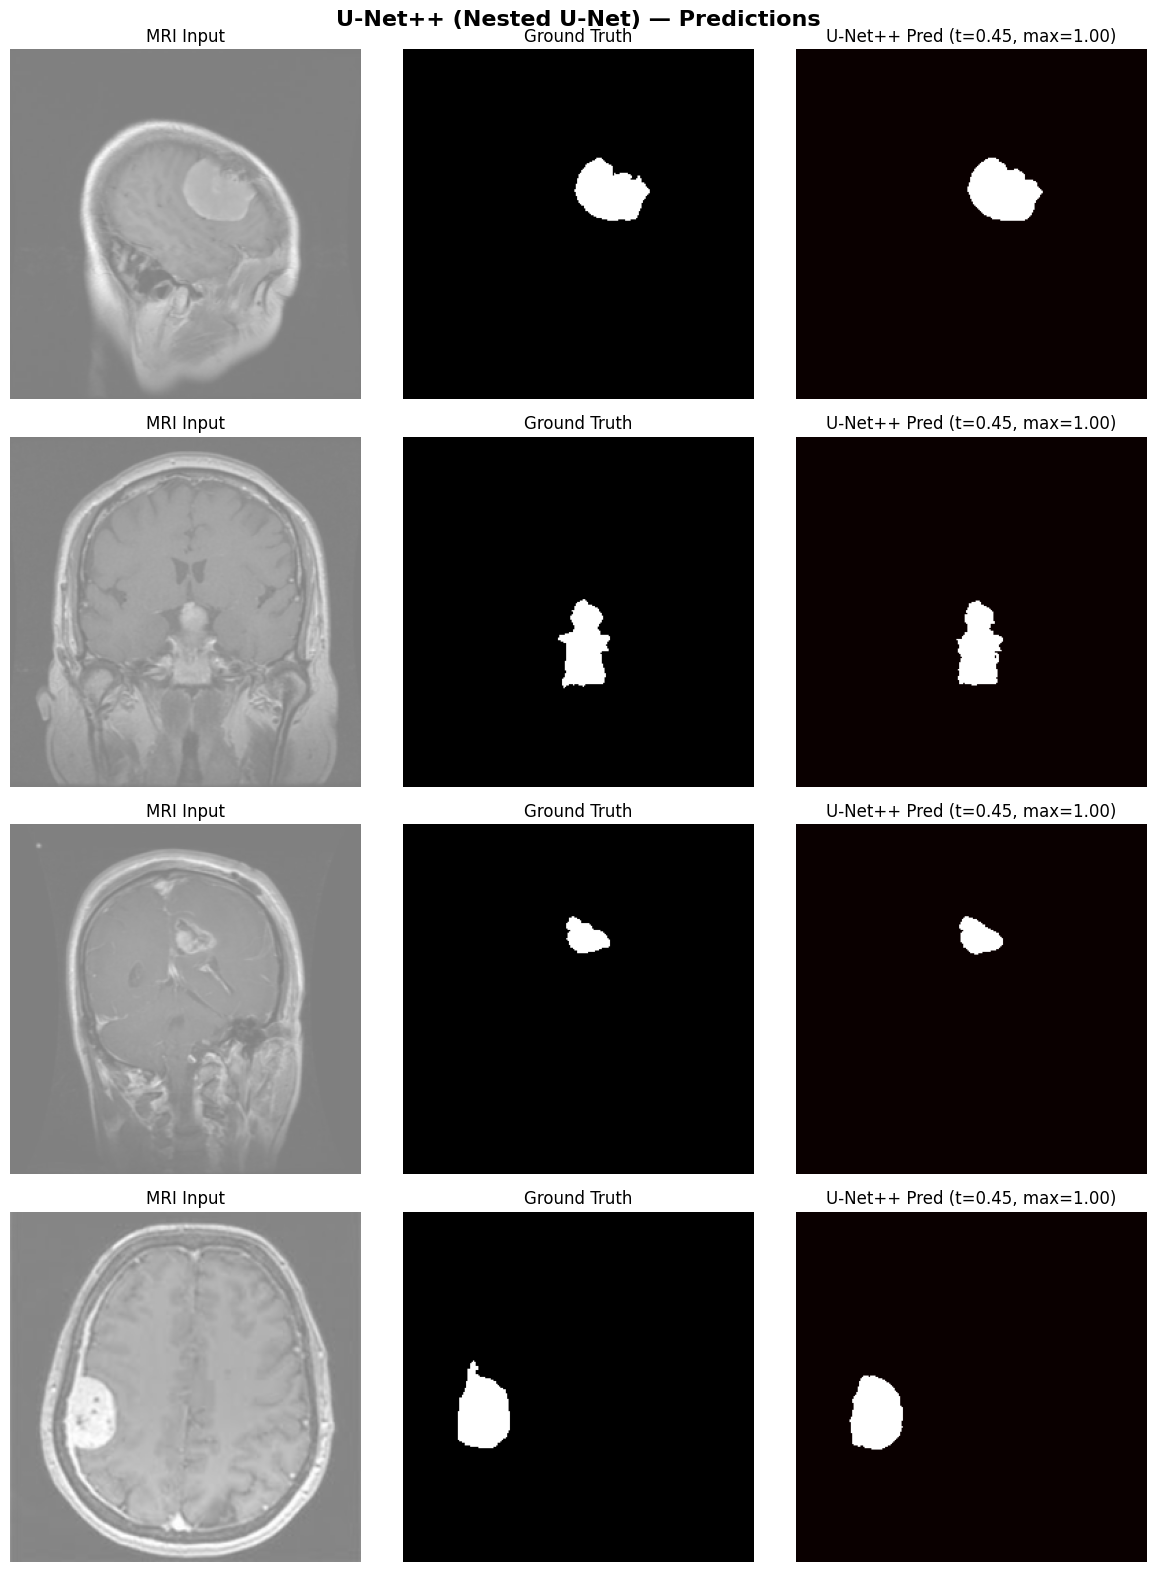

In [ ]:
import random
import matplotlib.pyplot as plt

test_dataset = test_loader.dataset
indices = random.sample(range(len(test_dataset)), 4)

fig, axes = plt.subplots(4, 3, figsize=(12, 16))
fig.suptitle('U-Net++ (Nested U-Net) — Predictions', fontsize=16, fontweight='bold')

for row, idx in enumerate(indices):
    img_tensor, mask_tensor = test_dataset[idx]
    img_input = img_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(img_input)
        pred = torch.sigmoid(logits).squeeze().cpu().numpy()

    # De-normalize image for plotting
    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    img_np = (img_np * 0.5 + 0.5).clip(0, 1)
    gt_mask = mask_tensor.squeeze().cpu().numpy()

    # MRI input
    axes[row, 0].imshow(img_np)
    axes[row, 0].set_title('MRI Input')
    axes[row, 0].axis('off')

    # Ground truth
    axes[row, 1].imshow(gt_mask, cmap='gray')
    axes[row, 1].set_title('Ground Truth')
    axes[row, 1].axis('off')

    # Predicted mask
    axes[row, 2].imshow(pred > best_t, cmap='hot')
    axes[row, 2].set_title(f'U-Net++ Pred (t={best_t:.2f}, max={pred.max():.2f})')
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()